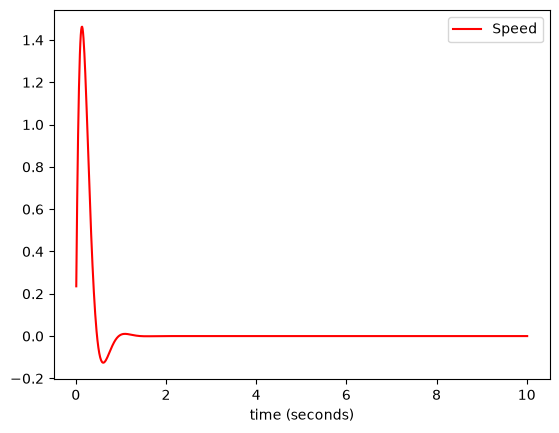

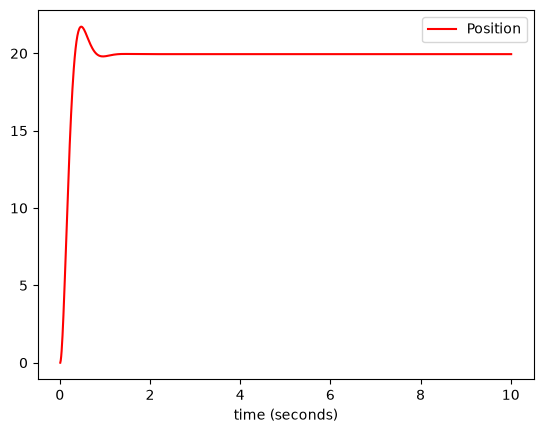

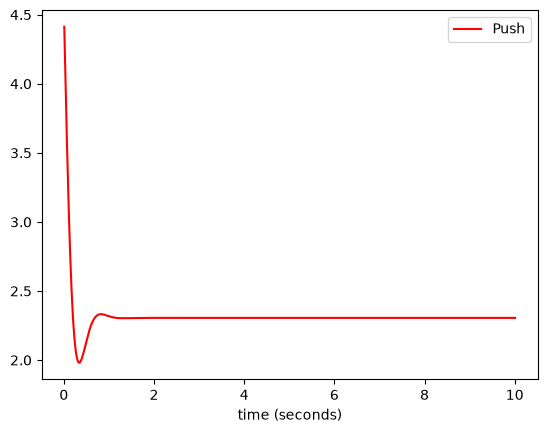

In [12]:
#
# to be tested with godot/cart-1d-no-physics
#

#
# CART 1D WITH IMPULSIVE INPUT
#

import numpy as np
import arslabrobotics as ar
import scipy.optimize as opt

class MPC_Arm:

    def __init__(self):
        self.model_arm = ar.system.Arm(1.0, 0.5, 0.9)
        self.Q = np.array([5.0, 0.0])  # Peso alto su errore posizione, basso su velocità
        self.R = 0.1                    # Peso sull'azione di controllo (energia)
        self.N = 20
        self.target = np.array([0.0, 0.0])
        self.delta_t = 0.05
        self.initial_state = [0.0, 0.0]
        
        # Vincoli fisici sulla spinta del motore (es. max +-25 Newton)
        self.max_force = 25.0

    def set_target(self, p, v):
        self.target = np.array([ p , v ]).T

    def opt_fun(self, u_array):
        #print(u_array)
        self.model_arm.theta = self.initial_state[0]
        self.model_arm.omega = self.initial_state[1]
        total_cost = 0
        for i in range(self.N):
            u = u_array[i]
            
            # compute error
            err_t = self.target[0] - self.model_arm.theta
            err_w = self.target[1] - self.model_arm.omega
            
            # quadratic cost function: J = x^T*Q*x + u^T*R*u
            cost = (self.Q[0] * (err_t ** 2)) + (self.Q[1] * (err_w ** 2)) + (self.R * (u ** 2))
            total_cost += cost
            
            self.model_arm.evaluate(self.delta_t, u)
        #print(cost)
        return total_cost

    def optimize(self, delta_t, initial_u, t, w):
        self.initial_state = [t, w]
        self.delta_t = delta_t

        # Initial vector based on last command 
        u_init = np.array([initial_u] * self.N)
        
        # Bounds of the input (saturation)
        bounds = opt.Bounds([-self.max_force] * self.N, [self.max_force] * self.N)
        
        result = opt.minimize(self.opt_fun, u_init, method='SLSQP', bounds=bounds)
        #print(result)
        return result.x
            
    

spd = ar.data.DataPlotter()
spd.set_x("time (seconds)")
spd.add_y("speed", "Speed")

pos = ar.data.DataPlotter()
pos.set_x("time (seconds)")
pos.add_y("pos", "Position")

push = ar.data.DataPlotter()
push.set_x("time (seconds)")
push.add_y("push", "Push")

arm = ar.system.Arm(1.0, 0.5, 0.9)

ctrl = MPC_Arm()
ctrl.set_target(np.radians(30),0)

#ctrl.optimize(0.1, 100, 0, 0)


t = ar.utils.Time(use_fake_time=True)
t.start()
force = 25
while t.get() < 10:

    t.sleep(0.01)
    delta_t = t.elapsed()

    force_array = ctrl.optimize(delta_t, force, arm.theta, arm.omega)
    
    force = force_array[0]
    
    (p, v) = arm.evaluate(delta_t, force)
    
    spd.append_x(t.get())
    spd.append_y("speed", v)
    
    pos.append_x(t.get())
    pos.append_y("pos", np.degrees(p))

    push.append_x(t.get())
    push.append_y("push", force)
    
spd.plot()
pos.plot()
push.plot()